# Esercizio 3) Regressione multipla

## Consegna: 
A partire dal dataset contenuto nel file `housing1.csv`, analizza i dati del dataframe e crea il modello di regressione lineare *multipla* per predire il prezzo delle case (feature `median_house_value`).

In particolare:
- importa i dati dal file con la funzione di `pandas`;
- guarda alle dimensioni del dataset e alle sue prime righe;
- utilizzando la funzione `scatter_matrix` di `pandas.plotting`, guarda se e come correlano le variabili del dataset fra loro;
- dividi i dati per la regressione fra variavili indipendenti (variabile `X`) e variabile dipendente (variabile `y`), poi separa i dati per train e test;
- sfruttando la funzione `LinearRegression` di `sklearn.linear_model`, calcola la regressione multipla sul train set e analizza i coefficienti calcolati: *quali features fanno aumentare il prezzo medio delle case? Quali abbassano il costo e quali non incidono sul prezzo?*
- fai testing, poi analizza i residui e calcola le metriche di R-quadro e MSE.

Ripeti la regressione multipla sul dataset dell'esercizio 2, per predire `Life_expectancy`.


**Features del dataset.** Ogni osservazione descrive una area censuaria della California. I dati sono relativi al 1990. Le features sono:
- `longitude` e `latitude`: coordinate geografiche dell'area;
- `housing_median_age`: anni (in media) delle abitazioni;
- `total_rooms`: num totale delle camere nell'area; 
- `total_bedrooms`: num totale delle camere da letto nell'area;
- `population`: popolazione nell'area (unità);
- `households`: num dei nuclei familiari nell'area;
- `median_income`: media degli stipendi, per 10K dollcari;
- `ocean_proximity`: indice di vicinanza dell'area all'oceano; ha valori in {0,1,2,3,4}.

## Caricamento dei dati

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt


In [3]:
df=pd.read_csv("housing1.csv")

print(type(df))

<class 'pandas.DataFrame'>


In [4]:
print("Prime righe del dataframe:")
print(df.head())

Prime righe del dataframe:
   Unnamed: 0  longitude  latitude  housing_median_age  total_rooms  \
0           0    -122.23     37.88                41.0        880.0   
1           1    -122.22     37.86                21.0       7099.0   
2           2    -122.24     37.85                52.0       1467.0   
3           3    -122.25     37.85                52.0       1274.0   
4           4    -122.25     37.85                52.0       1627.0   

   total_bedrooms  population  households  median_income  median_house_value  \
0           129.0       322.0       126.0         8.3252            452600.0   
1          1106.0      2401.0      1138.0         8.3014            358500.0   
2           190.0       496.0       177.0         7.2574            352100.0   
3           235.0       558.0       219.0         5.6431            341300.0   
4           280.0       565.0       259.0         3.8462            342200.0   

   ocean_proximity  
0                3  
1                3  
2 

In [5]:
print( df.shape )

(20640, 11)


## Analisi delle variabili disponibili e visualizzazioni

#### 1. Tutte le variabili

Vediamo tutte le combinazioni di scatterplot 2D con `scatter_matrix` che fa parte di pandas. Più precisamente, lo troviamo in `pandas.plotting` che è incluso in pandas (quindi non va installato separatamente e ci basta importare la funzione che ci serve).

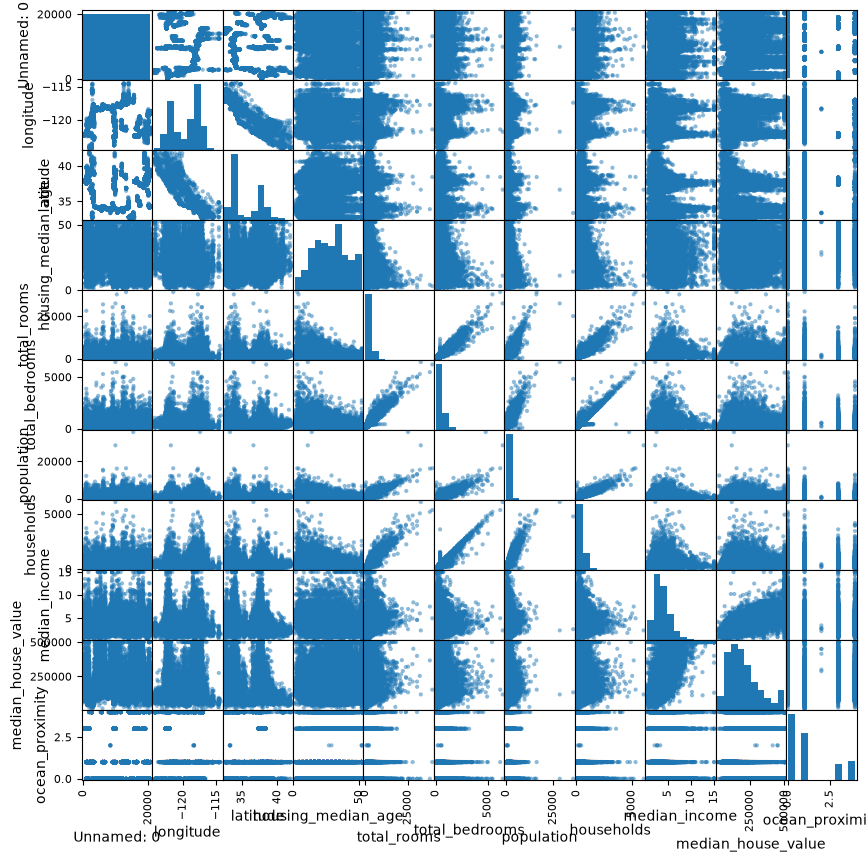

In [6]:
from pandas.plotting import scatter_matrix

scatter_matrix(df, figsize=(10, 10), diagonal="hist")
plt.show()

#### 2. La variabile dipendente (da predire)


In [7]:
y = df["median_house_value"]

In [8]:
print(type(y))
print(y.size)


<class 'pandas.Series'>
20640


In [55]:
print( y )

0        452600.0
1        358500.0
2        352100.0
3        341300.0
4        342200.0
           ...   
20635     78100.0
20636     77100.0
20637     92300.0
20638     84700.0
20639     89400.0
Name: median_house_value, Length: 20640, dtype: float64


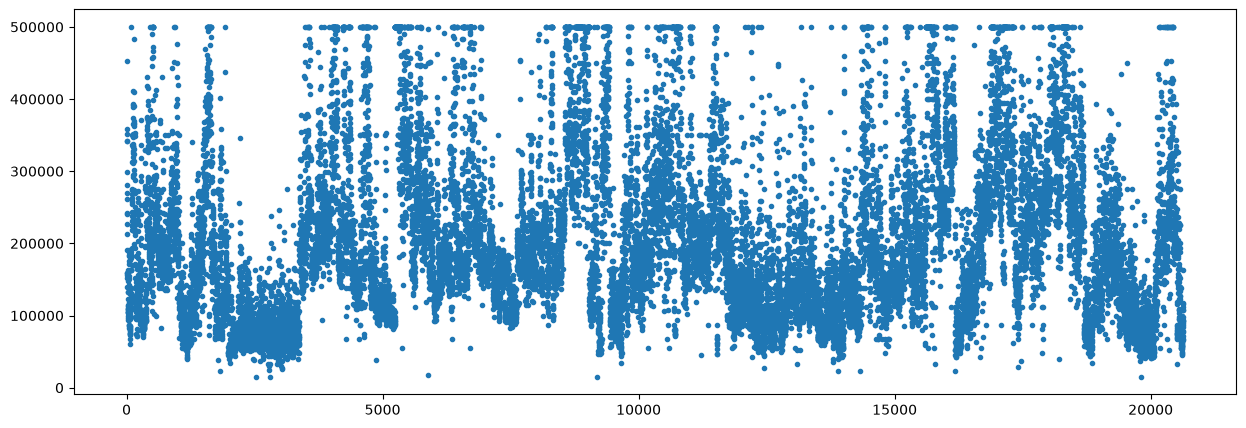

In [9]:
plt.figure(figsize=(15,5))
plt.plot(y, '.')
plt.show()

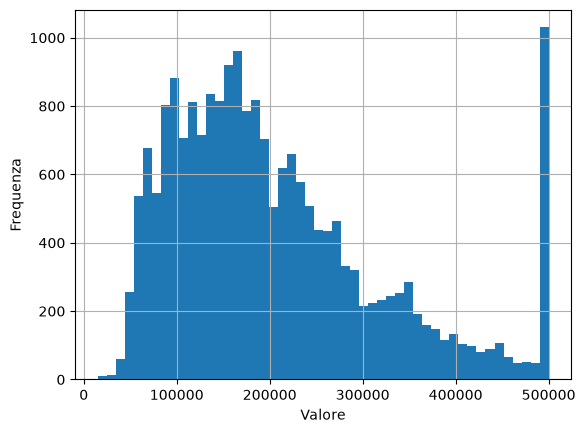

In [10]:
y.hist(bins=50)

plt.xlabel("Valore")
plt.ylabel("Frequenza")
plt.show()

## Preprocessing

In [11]:
# Estraggo i dati in X
X = df.drop("median_house_value",axis=1)  # Variabili indipendenti
print(X)

       Unnamed: 0  longitude  latitude  housing_median_age  total_rooms  \
0               0    -122.23     37.88                41.0        880.0   
1               1    -122.22     37.86                21.0       7099.0   
2               2    -122.24     37.85                52.0       1467.0   
3               3    -122.25     37.85                52.0       1274.0   
4               4    -122.25     37.85                52.0       1627.0   
...           ...        ...       ...                 ...          ...   
20635       20635    -121.09     39.48                25.0       1665.0   
20636       20636    -121.21     39.49                18.0        697.0   
20637       20637    -121.22     39.43                17.0       2254.0   
20638       20638    -121.32     39.43                18.0       1860.0   
20639       20639    -121.24     39.37                16.0       2785.0   

       total_bedrooms  population  households  median_income  ocean_proximity  
0               129

In [12]:
# Estraggo il target
y = df["median_house_value"]  # Variabile dipendente



## Train e Test

In [13]:
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import train_test_split

In [14]:
# Divido il dataset in set di addestramento e di test
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
print( X_train.shape)
print( X_test.shape)

(16512, 10)
(4128, 10)


Train

In [15]:
# Creo il modello di regressione lineare multipla
model = LinearRegression()

# Addestro il modello sul set di addestramento
model.fit(X_train, y_train)

print(model)

LinearRegression()


Guardo ai coefficienti di regressione: ogni slope corrisponde a una colonna di X

In [16]:
print("Intercetta:", model.intercept_)   # c0
print("Slopes:", model.coef_)            # c1, ..., cp

Intercetta: -3539867.822049006
Slopes: [ 6.26250148e-01 -4.21286457e+04 -4.20616555e+04  1.25339748e+03
 -8.42970027e+00  1.16871468e+02 -3.86407695e+01  4.78024942e+01
  4.05430428e+04 -5.73652718e+02]


In [17]:
for nome, coefficiente in zip(X.columns, model.coef_):
    print(f"{nome}: {coefficiente:.4f}")

Unnamed: 0: 0.6263
longitude: -42128.6457
latitude: -42061.6555
housing_median_age: 1253.3975
total_rooms: -8.4297
total_bedrooms: 116.8715
population: -38.6408
households: 47.8025
median_income: 40543.0428
ocean_proximity: -573.6527


Test

In [44]:
# Valuto il modello sul set di test
y_pred = model.predict(X_test)

print(type(y_pred))
print(y_pred[:10])


<class 'numpy.ndarray'>
[ 70120.59302387 149796.6038227  256759.21554528 269426.86363026
 264475.06871195 156452.85272645 286302.32234057 223397.24760042
 258845.75766901 403203.12821786]


## Valutazione sul test set

#### 1. Residui

In [46]:
import numpy as np
r = y_test-y_pred

print('Somma abs(residui): \t', np.sum( np.abs(r) ))
print('Somma (residui)**2:\t', np.dot(r, r))
print('Media abs(residui): \t', np.mean( np.abs(r) ) )


Somma abs(residui): 	 214093430.87264264
Somma (residui)**2:	 20879737565613.09
Media abs(residui): 	 51863.718719147924


#### 2. R quadro
L'R quadro (R² o coefficiente di determinazione) è un indice statistico che misura quanta varianza della variabile dipendente (y) è spiegata dalle variabili indipendenti (X) in un modello di regressione.

Scala dei valori

- 0 (o 0%): Il modello non spiega alcuna variabilità dei dati; la previsione non è migliore della semplice media.
- 1 (o 100%): Spiegazione perfetta; tutti i punti cadono esattamente sulla retta o curva di regressione.
- Valori negativi (R² < 0): Si verificano quando il modello è peggio del semplice utilizzo della media come predittore (di solito a causa di assenza di intercetta o specifiche formule).

In [41]:
from sklearn.metrics import r2_score

print("R-squared:", r2_score(y_test, y_pred))


R-squared: 0.6140078368928703


#### 3. MSE

L'MSE (Mean Squared Error, in italiano Errore Quadratico Medio) è un'ulteriore metrica utilizzata in statistica e nel machine learning per misurare la precisione di un modello di regressione. Calcola la differenza tra ogni valore reale e il relativo valore previsto, la eleva al quadrato e poi calcola la media di tutti i risultati.

Scala dei valori: 
- più il valore dell'MSE è basso, migliore è il modello: un MSE pari a 0 indica una precisione perfetta.
- non esiste un upper bound (limite massimo) predefinito dell'MSE: l'entità di ogni errore dipende dal range dei valori di y. Inoltre, elevando al quadrato gli errori, i valori anomali (outliers) vengono penalizzati molto pesantemente rispetto agli errori piccoli e l'MSE cresce.

In [42]:
from sklearn.metrics import mean_squared_error

print("Mean Squared Error:", mean_squared_error(y_test, y_pred))


Mean Squared Error: 5058075960.662086


In [ ]:
print('Somma(residui)**2 / n_test:\t', np.dot(r, r)/ y_test.size)

Somma (residui)**2 / n_test:	 5058075960.662086
